In [ ]:
import pandas as pd
from datetime import datetime


In [349]:

df_hydro = pd.read_excel("/Users/6256481/Code/river-hierarchy/SWORD_gauge_match/outputs/mask_hydro_quality.xlsx", sheet_name = 'Hydrograph_quality')
df_hydro = df_hydro[(~df_hydro['Peak_quality'].isin(['Bad', '-'])) & (~df_hydro['Peak_match'].isin(['Bad', '-']))]
df_hydro = df_hydro[['Example', 'Up', 'Period_start', 'Period_end', 'Orientation', 'Forcing_time','mask_file']]

# mask prepping

In [346]:
ex_id = 22
row = df_hydro[df_hydro['Example'] == ex_id].iloc[0]

if ex_id < 10:
  ex_id_str = f'0{ex_id}'
else:
  ex_id_str = str(ex_id)
################################################
# Mask prep: Create binary mask from selected mask
################################################
mask_prep_string = rf"""/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python -B \
  rivgraph_centerline/run_workflow.py prepare-mask \
  --name {ex_id_str} \
  --source-mask /Volumes/PhD/river_hierarchy/data/water_masks/{row['mask_file']}"""
print("Mask prep: create binary mask with correct crs\n")
print(mask_prep_string)
print('\n\n')

PYTHON = "/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python"
import subprocess

def run_cmd(label, cmd, env=None):
        print(f"\n{'=' * 80}")
        print(label)
        print(" ".join(map(str, cmd)))
        print(f"{'=' * 80}\n")

        subprocess.run(
            cmd,
            check=True,
            env=env,
        )

mask_prep_cmd = [
    PYTHON,
    "-B",
    "rivgraph_centerline/run_workflow.py",
    "prepare-mask",
    "--name", ex_id_str,
    "--source-mask", f"/Volumes/PhD/river_hierarchy/data/water_masks/{row['mask_file']}",
    "--threshold", "20"
]
run_cmd("mask prepping", mask_prep_cmd)

Mask prep: create binary mask with correct crs

/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python -B \
  rivgraph_centerline/run_workflow.py prepare-mask \
  --name 22 \
  --source-mask /Volumes/PhD/river_hierarchy/data/water_masks/example_22_2020Q2_max_water_uint8.tif




mask prepping
/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python -B rivgraph_centerline/run_workflow.py prepare-mask --name 22 --source-mask /Volumes/PhD/river_hierarchy/data/water_masks/example_22_2020Q2_max_water_uint8.tif --threshold 20



python(57061) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


{
  "command": "prepare-mask",
  "run_paths": {
    "run_dir": "/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22",
    "prepared_mask": "/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22/masks_prepared/22_binary_projected.tif",
    "manual_edits_path": "/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22/manual_edits/22_manual_edits.gpkg",
    "cleaned_mask": "/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22/masks_cleaned/22_cleaned.tif",
    "rivgraph_dir": "/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22/rivgraph",
    "prepare_summary": "/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22/prepare_summary.json",
    "manual_edits_summary": "/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22/manual_edits_summary.json",
    "rivgraph_summary": "/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22/rivgraph_summary.jso

In [203]:
import rasterio
mask_prep = f'/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/{ex_id}/masks_prepared/{ex_id}_binary_projected.tif'


with rasterio.open(mask_prep) as src:
    print("CRS as EPSG:", src.crs.to_epsg() if src.crs else None)

CRS as EPSG: 32605


# Single commands

In [351]:
ex_id = 22

row = df_hydro[df_hydro['Example'] == ex_id].iloc[0]

if ex_id < 10:
    ex_id = f'0{ex_id}'
mask_id = ex_id

orientation = row['Orientation']

def change_timestamp(dt_str):
  dt = datetime.strptime(dt_str, "%Y-%m-%d %H:%M:%S%z")
  return dt.strftime("%Y-%m-%dT%H:%M:%SZ")

STATION_KEY = row['Up']
start_time  = change_timestamp(row['Period_start'])
end_time    = change_timestamp(row['Period_end'])
forcing_time = int(row['Forcing_time'])

################################################
# Apply edits from created polygons:
# - polygon file: "example_name"_manual_edits
# - add "action" field: commands = add, remove
# - crs: crs of prepped file

# create base centerline file
################################################
edits_run_rivgraph = rf"""/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python -B \
  rivgraph_centerline/run_workflow.py apply-edits \
  --name {ex_id} \
    
  MPLCONFIGDIR=/tmp/matplotlib-rivgraph \
  /opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python -B \
  rivgraph_centerline/run_workflow.py run-rivgraph \
  --name {ex_id} \
  --exit-sides {orientation} \
  --run-dir rivgraph_centerline/outputs/runs/{ex_id} \
  --assign-flow \
  --flow-mesh-mode auto"""
print("apply edits and Run base rivgraph\n")
print(edits_run_rivgraph)
print('\n\n')

################################################
# unit detection
################################################
level_detection_string_comb = ''
for nv in ['independent-units','compound-bubbles']:
  if nv == 'compound-bubbles':
    nv_ = 'compound_bubbles'
    nvs = 'compound_bubbles'

  elif nv == 'independent-units':
      nv_ = 'independent_units'
      nvs = 'indep'
    
  level_detection_string = rf"""/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python \
    network_variants/run_collapse_experiment.py \
    {nv} \
    --cleaned-mask rivgraph_centerline/outputs/runs/{ex_id}/masks_cleaned/{ex_id}_cleaned.tif \
    --reviewed-links /Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/{ex_id}/rivgraph/{ex_id}_links.gpkg \
    --reviewed-nodes /Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/{ex_id}/rivgraph/{ex_id}_nodes.gpkg \
    --exit-sides {orientation} \
    --experiment-id {ex_id}_{nv_} \
    --output-dir network_variants/output/{ex_id}_{nvs} \
    --sword-node-source /Volumes/PhD/SWORD/v17c/ \
    --sword-example-stations-source SWORD_gauge_match/outputs/hierarchy_examples_filtered_subdaily_manual_updates_final.gpkg \
    --sword-station-match-source SWORD_gauge_match/outputs/selected_event_stations_same_main_path.gpkg \
    --sword-reach-buffer-steps 2 \
    --sword-wse-field wse_obs_p50 \
    --slope-profile-mode reference_section \
    --min-slope 1e-6 \
    --max-slope-for-k 0.009 \
    --section-slope-ratio-max 5 \
    --equivalent-length-field len \
    --compute-equivalent-resistance \
    --equivalent-resistance-law chezy \
    --equivalent-geometry-method wide \
    --equivalent-chezy-cz 22 \
    --equivalent-kb-mode based_reference_section \
    --equivalent-forcing-path SWORD_gauge_match/outputs/subdaily_values/{STATION_KEY[0:2]}/subdaily_timeseries.parquet \
    --equivalent-forcing-station-key {STATION_KEY} \
    --equivalent-station-key-column station_key \
    --equivalent-time-column time \
    --equivalent-discharge-column discharge \
    --equivalent-forcing-start-time {start_time} \
    --equivalent-forcing-end-time {end_time} \
    --equivalent-forcing-resample-minutes {forcing_time} \
    --equivalent-forcing-output-cache-dir SWORD_gauge_match/outputs/rapid_forcing_cache \
    --equivalent-kb-model-path RAPID/assets/based_model_v2.ubj \
    --equivalent-kb-width-sample-field width_wet \
    --equivalent-kb-width-percentile 90 \
    --collapse-corridor-mode anchored"""


  level_detection_string_comb += level_detection_string
  level_detection_string_comb += '\n\n'

     
print("Unit detection\n")
print(level_detection_string_comb)
print('\n\n')

print('RUN RAPID & K equivalent')
run_cmd = ''

for nv in ['independent-units','compound-bubbles']:
  if nv == 'compound-bubbles':
    nv_ = 'compound_bubbles'
    nvs = 'compound_bubbles'

  elif nv == 'independent-units':
      nv_ = 'independent_units'
      nvs = 'indep'
  # for anchor in ['anchored', 'realized']:
  for anchor in ['anchored']:
    variant_dir = f"/Users/6256481/Code/river-hierarchy/network_variants/output/{ex_id}_{nvs}__{anchor}"

    # ################################################
    # # K calculations
    # ################################################
    k_equivalent = rf"""/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python \
        network_variants/run_equivalent_resistance_experiment.py \
        {variant_dir} \
        --equivalent-length-field len \
        --equivalent-resistance-law chezy \
        --equivalent-geometry-method wide \
        --equivalent-chezy-cz 22 \
        --equivalent-kb-mode based_reference_section \
        --equivalent-forcing-path SWORD_gauge_match/outputs/subdaily_values/{STATION_KEY[0:2]}/subdaily_timeseries.parquet \
        --equivalent-forcing-station-key {STATION_KEY} \
        --equivalent-station-key-column station_key \
        --equivalent-time-column time \
        --equivalent-discharge-column discharge \
        --equivalent-forcing-start-time {start_time} \
        --equivalent-forcing-end-time {end_time} \
        --equivalent-forcing-resample-seconds {forcing_time} \
        --equivalent-forcing-output-cache-dir SWORD_gauge_match/outputs/rapid_forcing_cache \
        --equivalent-kb-model-path RAPID/assets/based_model_v2.ubj \
        --equivalent-kb-width-sample-field width_wet \
        --equivalent-kb-width-percentile 90"""
      
    run_cmd += k_equivalent
    run_cmd += '\n\n'
    ################################################
    # Run Rapid prep
    ################################################
    base_rapid_prep = rf"""/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python \
      RAPID/run_prepare_experiment.py \
      {variant_dir} \
      --forcing-path SWORD_gauge_match/outputs/subdaily_values/{STATION_KEY[0:2]}/subdaily_timeseries.parquet \
      --forcing-station-key {STATION_KEY} \
      --station-key-column station_key \
      --time-column time \
      --discharge-column discharge \
      --forcing-start-time {start_time} \
      --forcing-end-time {end_time} \
      --forcing-resample-seconds {forcing_time} \
      --forcing-output-cache-dir SWORD_gauge_match/outputs/rapid_forcing_cache \
      --kb-mode based_reference_section \
      --kb-model-path RAPID/assets/based_model_v2.ubj \
      --kb-width-sample-field width_wet \
      --kb-width-percentile 90 \
      --use-celerity-capping \
      --min-celerity-mps 0.070 \
      --max-celerity-mps 2.524 \
      --target-subreach-length-m 200 \
      --min-effective-length-for-k-m 200 \
      --vary-width-by-subreach \
      --auto-spinup-from-k \
      --spinup-k-multiplier 1.1 \
      --subreach-width-sample-field width_wet"""

    run_cmd += base_rapid_prep
    run_cmd += '\n\n'
    ################################################
    # Run Rapid
    ################################################
    run_rapid_string = rf"""/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python \
      RAPID/run_rapid_experiment.py \
      {variant_dir}"""
    run_cmd += run_rapid_string
    run_cmd += '\n\n'

print(run_cmd)

apply edits and Run base rivgraph

/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python -B \
  rivgraph_centerline/run_workflow.py apply-edits \
  --name 22 \

  MPLCONFIGDIR=/tmp/matplotlib-rivgraph \
  /opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python -B \
  rivgraph_centerline/run_workflow.py run-rivgraph \
  --name 22 \
  --exit-sides NS \
  --run-dir rivgraph_centerline/outputs/runs/22 \
  --assign-flow \
  --flow-mesh-mode auto



Unit detection

/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python \
    network_variants/run_collapse_experiment.py \
    independent-units \
    --cleaned-mask rivgraph_centerline/outputs/runs/22/masks_cleaned/22_cleaned.tif \
    --reviewed-links /Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22/rivgraph/22_links.gpkg \
    --reviewed-nodes /Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/22/rivgraph/22_nodes.gpkg \
    --exit-sides NS \
    --experiment-id 22_independent_units \
    --output-di

In [191]:
d= pd.read_csv('/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S000_base/rapid/prep/rapid_link_attributes.csv')

'/Users/6256481/Code/river-hierarchy/network_variants/output/03_indep__anchored/states/S000_base/variant/directed/03__S000_base_directed_links.gpkg'

In [354]:
from glob import glob
from pathlib import Path
import numpy as np
ex = '21'
# ut = f'{ex}_compound_bubbles__anchored'
ut = f'{ex}_indep__anchored'
base = f"/Users/6256481/Code/river-hierarchy/network_variants/output/{ut}/states/"



gpkg_paths = glob(base + "**/variant/directed/*directed_links.gpkg*", recursive = True)
def sort_key(path):
    token = path.split('_')[-3]
    if token == "base":
        return 0
    return int(token) + 1

gpkg_paths_sorted = sorted(gpkg_paths, key=sort_key)
gpkg_paths_sorted

['/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S000_base/variant/directed/21__S000_base_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S020_unit_1/variant/directed/21__S020_unit_1_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S025_unit_2/variant/directed/21__S025_unit_2_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S011_unit_3/variant/directed/21__S011_unit_3_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S021_unit_4/variant/directed/21__S021_unit_4_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S004_unit_5/variant/directed/21__S004_unit_5_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__an

In [ ]:
from qgis.core import QgsVectorLayer, QgsProject
import os

gpkg_paths =['/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S000_base/variant/directed/21__S000_base_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S020_unit_1/variant/directed/21__S020_unit_1_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S025_unit_2/variant/directed/21__S025_unit_2_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S011_unit_3/variant/directed/21__S011_unit_3_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S021_unit_4/variant/directed/21__S021_unit_4_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S004_unit_5/variant/directed/21__S004_unit_5_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S010_unit_6/variant/directed/21__S010_unit_6_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S019_unit_7/variant/directed/21__S019_unit_7_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S001_unit_8/variant/directed/21__S001_unit_8_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S016_unit_9/variant/directed/21__S016_unit_9_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S008_unit_10/variant/directed/21__S008_unit_10_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S006_unit_11/variant/directed/21__S006_unit_11_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S024_unit_12/variant/directed/21__S024_unit_12_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S003_unit_13/variant/directed/21__S003_unit_13_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S012_unit_14/variant/directed/21__S012_unit_14_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S002_unit_15/variant/directed/21__S002_unit_15_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S018_unit_16/variant/directed/21__S018_unit_16_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S017_unit_17/variant/directed/21__S017_unit_17_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S007_unit_18/variant/directed/21__S007_unit_18_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S015_unit_19/variant/directed/21__S015_unit_19_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S009_unit_20/variant/directed/21__S009_unit_20_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S022_unit_21/variant/directed/21__S022_unit_21_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S013_unit_22/variant/directed/21__S013_unit_22_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S014_unit_23/variant/directed/21__S014_unit_23_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S005_unit_24/variant/directed/21__S005_unit_24_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S026_unit_25/variant/directed/21__S026_unit_25_directed_links.gpkg',
 '/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S023_unit_26/variant/directed/21__S023_unit_26_directed_links.gpkg']

project = QgsProject.instance()
root = project.layerTreeRoot()

for path in gpkg_paths:
    layer_name = os.path.splitext(os.path.basename(path))[0]
    layer = QgsVectorLayer(path, layer_name, "ogr")

    if layer.isValid():
        project.addMapLayer(layer)

        # Untick visibility in the Layers panel
        node = root.findLayer(layer.id())
        if node:
            node.setItemVisibilityChecked(False)

    else:
        print(f"Could not load: {path}")

In [192]:
slope = d.groupby('id_link', as_index = False).first()
slope[slope['id_link'] == 81]['slope_used'].iloc[0]

/var/folders/bs/xx1t3fn91jl3k26fn1pndd_c0000gn/T/ipykernel_36747/298505726.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  slope = d.groupby('id_link', as_index = False).first()


np.float64(6.574342583899934e-06)

In [193]:
dd = d[d['rapid_celerity_capped'] == True]
dd['id_link'].unique()

array([11, 12, 43, 64, 72, 80, 81, 82, 88])

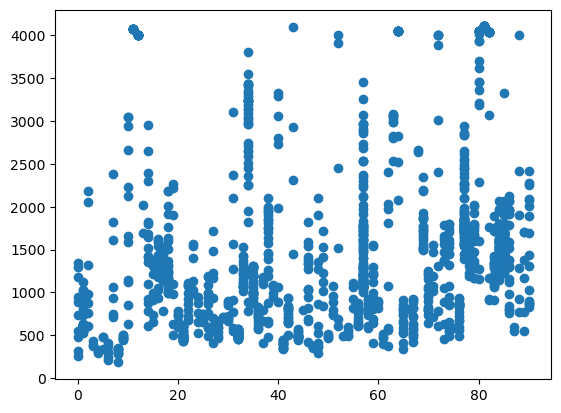

In [173]:
plt.scatter(d['id_link'], d['rapid_k'])

In [195]:
from pathlib import Path
import pandas as pd
import numpy as np

p = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__realized/states/S000_base/rapid/prep/rapid_link_attributes.csv")
df = pd.read_csv(p)

df["delta_h_used_m"] = df["slope_used"] * df["rapid_effective_length_m"]
df["delta_h_raw_m"] = df["raw_slope"] * df["rapid_effective_length_m"]
df["delta_h_section_ref_m"] = df["slope_section_ref"] * df["rapid_effective_length_m"]
df["slope_to_section_ratio"] = df["slope_used"] / df["slope_section_ref"]

cols = [
    "id_link",
    "rapid_k",
    "rapid_celerity_mps",
    "rapid_width_m",
    "rapid_effective_length_m",
    "slope_used",
    "raw_slope",
    "slope_section_ref",
    "delta_h_used_m",
    "delta_h_raw_m",
    "delta_h_section_ref_m",
    "slope_to_section_ratio",
    "slope_source_method",
    "slope_reason",
    "rapid_celerity_capped",
]

worst = df.sort_values("rapid_k", ascending=False)[cols].head(30)
worst


,id_link,rapid_k,rapid_celerity_mps,rapid_width_m,rapid_effective_length_m,slope_used,raw_slope,slope_section_ref,delta_h_used_m,delta_h_raw_m,delta_h_section_ref_m,slope_to_section_ratio,slope_source_method,slope_reason,rapid_celerity_capped
1081,81,4103.494370,0.05,536.276803,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True
1088,81,4103.494370,0.05,695.936072,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True
1097,81,4103.494370,0.05,852.297062,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True
1096,81,4103.494370,0.05,871.449805,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True
1095,81,4103.494370,0.05,842.720690,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True
1094,81,4103.494370,0.05,842.720690,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True
1093,81,4103.494370,0.05,847.508876,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True
1092,81,4103.494370,0.05,842.720690,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True
1090,81,4103.494370,0.05,749.469616,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True
1089,81,4103.494370,0.05,727.804232,205.174718,0.000007,0.000007,0.000238,0.001349,0.001349,0.048907,0.027581,raw_wse,ok,True


In [196]:
S = df.groupby('id_link').first()['slope_used']
S.max()/ S.min(),S.max(), S.min() 

(199.17423630104372, 0.0013094396633297, 6.574342583899934e-06)

In [197]:
node_p = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__realized/states/S000_base/hydraulic_context/node_hydraulic_context.csv")
nodes = pd.read_csv(node_p)

nodes[[
    "id_node",
    "node_wse_raw",
    "rapid_wse_for_slope",
    "rapid_wse_interpolated",
    "rapid_wse_source_method",
    "rapid_wse_profile_residual",
    "node_network_dist_out_m",
]].head(30)



,id_node,node_wse_raw,rapid_wse_for_slope,rapid_wse_interpolated,rapid_wse_source_method,rapid_wse_profile_residual,node_network_dist_out_m
0,54,161.006240,161.006240,False,profile_monotone_requested_field_nodes,0.000000,44237.688732
1,55,160.434098,160.434098,False,profile_monotone_requested_field_nodes,0.000000,39396.438429
2,53,161.030520,161.030520,False,profile_monotone_requested_field_nodes,0.000000,47930.833664
3,51,161.417960,161.417960,False,profile_monotone_requested_field_nodes,0.000000,52388.678805
4,59,158.688810,158.688810,False,profile_monotone_requested_field_nodes,0.000000,22129.451612
5,52,161.753800,161.753800,False,profile_monotone_requested_field_nodes,0.000000,56262.296885
6,60,158.428585,158.428585,False,profile_monotone_requested_field_nodes,0.000000,20444.739170
7,58,158.585080,158.585080,False,profile_monotone_requested_field_nodes,0.000000,21804.817456
8,49,162.773694,162.773694,False,profile_monotone_requested_field_nodes,0.000000,59892.208746
9,61,157.896690,157.896690,False,profile_monotone_requested_field_nodes,0.000000,17196.122355


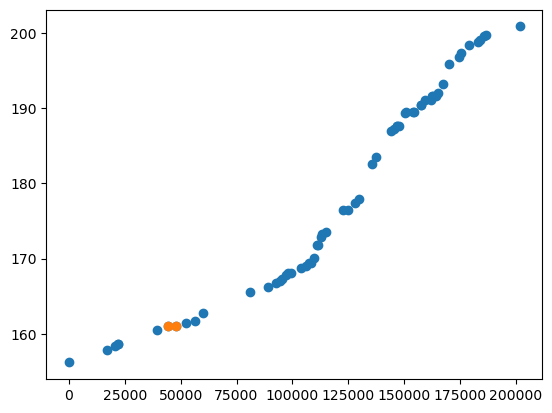

In [181]:
plt.scatter(nodes['node_network_dist_out_m'], nodes['rapid_wse_for_slope'])

plt.scatter(nodes.loc[nodes['id_node'].isin([53,54]), 'node_network_dist_out_m'], 
            nodes.loc[nodes['id_node'].isin([53,54]),'rapid_wse_for_slope'])

In [212]:
D = pd.read_csv('/Users/6256481/Code/river-hierarchy/network_variants/output/tmp_test_unit_7_anchored/matching/link_match.csv')
D.loc[D['child_id_link'] == 20, ['child_id_link', 'parent_id_link', 'parent_overlap_length', 'parent_overlap_fraction']]

,child_id_link,parent_id_link,parent_overlap_length,parent_overlap_fraction
90,20,22,2522.378066,1.000000
91,20,20,12.936065,0.008558
92,20,21,12.936065,0.022660
93,20,23,9.147179,0.004286
94,20,24,9.147179,0.086294


# Python run commands

In [ ]:
import subprocess
from pathlib import Path
import os

env_rivgraph = os.environ.copy()
env_rivgraph["MPLCONFIGDIR"] = "/tmp/matplotlib-rivgraph"
PYTHON = "/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python"

def run_cmd(label, cmd, env=None):
        print(f"\n{'=' * 80}")
        print(label)
        print(" ".join(map(str, cmd)))
        print(f"{'=' * 80}\n")

        subprocess.run(
            cmd,
            check=True,
            env=env,
        )
def create_CLI_commands(ex_id, nv, anchor):
    row = df_hydro[df_hydro['Example'] == ex_id].iloc[0]

    if ex_id < 10:
        ex_id = f'0{ex_id}'
    mask_id = ex_id

    orientation = row['Orientation']

    if nv == 'compound-bubbles':
        nv_ = 'compound_bubbles'
        nvs = 'compound_bubbles'

    elif nv == 'independent-units':
        nv_ = 'independent_units'
        nvs = 'indep'

    if anchor == True:
        anchored = 'anchored'
    else:
        anchored = 'realized'

    def change_timestamp(dt_str):
        dt = datetime.strptime(dt_str, "%Y-%m-%d %H:%M:%S%z")
        return dt.strftime("%Y-%m-%dT%H:%M:%SZ")

    STATION_KEY = row['Up']
    start_time  = change_timestamp(row['Period_start'])
    end_time    = change_timestamp(row['Period_end'])
    forcing_time = int(row['Forcing_time'])

    PYTHON = "/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python"

    ################################################
    # Mask prep: Create binary mask from selected mask
    ################################################
    mask_prep_cmd = [
        PYTHON,
        "-B",
        "rivgraph_centerline/run_workflow.py",
        "prepare-mask",
        "--name", str(ex_id),
        "--source-mask", f"/Volumes/PhD/river_hierarchy/data/water_masks/{row['mask_file']}",
    ]

    ################################################
    # Apply edits from created polygons:
    # - polygon file: "example_name"_manual_edits
    # - add "action" field: commands = add, remove
    # - crs: crs of prepped file
    ################################################
    apply_edits_cmd = [
        PYTHON,
        "-B",
        "rivgraph_centerline/run_workflow.py",
        "apply-edits",
        "--name", str(ex_id),
    ]

    ################################################
    # Create base centerline file
    ################################################
    run_rivgraph_cmd = [
        PYTHON,
        "-B",
        "rivgraph_centerline/run_workflow.py",
        "run-rivgraph",
        "--name", str(ex_id),
        "--exit-sides", str(orientation),
        "--run-dir", f"rivgraph_centerline/outputs/runs/{ex_id}",
        "--assign-flow",
    ]

    ################################################
    # Unit detection
    ################################################
    level_detection_cmd = [
        PYTHON,
        "network_variants/run_collapse_experiment.py",
        str(nv),
        "--cleaned-mask", f"rivgraph_centerline/outputs/runs/{ex_id}/masks_cleaned/{ex_id}_cleaned.tif",
        "--reviewed-links", f"/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/{ex_id}/rivgraph/{ex_id}_links.gpkg",
        "--reviewed-nodes", f"/Users/6256481/Code/river-hierarchy/rivgraph_centerline/outputs/runs/{ex_id}/rivgraph/{ex_id}_nodes.gpkg",
        "--exit-sides", str(orientation),
        "--experiment-id", f"{ex_id}_{nv_}",
        "--output-dir", f"network_variants/output/{ex_id}_{nvs}",
        "--sword-node-source", "/Volumes/PhD/SWORD/v17c/",
        "--sword-example-stations-source", "SWORD_gauge_match/outputs/hierarchy_examples_filtered_subdaily_manual_updates_final.gpkg",
        "--sword-station-match-source", "SWORD_gauge_match/outputs/selected_event_stations_same_main_path.gpkg",
        "--sword-reach-buffer-steps", "2",
        "--sword-wse-field", "wse_obs_p50",
        "--compute-equivalent-resistance",
        "--equivalent-resistance-law", "chezy",
        "--equivalent-geometry-method", "wide",
        "--equivalent-chezy-cz", "22",
        "--equivalent-kb-mode", "based_reference_section",
        "--equivalent-forcing-path", f"SWORD_gauge_match/outputs/subdaily_values/{STATION_KEY[0:2]}/subdaily_timeseries.parquet",
        "--equivalent-forcing-station-key", str(STATION_KEY),
        "--equivalent-station-key-column", "station_key",
        "--equivalent-time-column", "time",
        "--equivalent-discharge-column", "discharge",
        "--equivalent-forcing-start-time", str(start_time),
        "--equivalent-forcing-end-time", str(end_time),
        "--equivalent-forcing-resample-minutes", "18",
        "--equivalent-forcing-output-cache-dir", "SWORD_gauge_match/outputs/rapid_forcing_cache",
        "--equivalent-kb-model-path", "RAPID/assets/based_model_v2.ubj",
        "--equivalent-kb-width-sample-field", "width_wet",
        "--equivalent-kb-width-percentile", "90",
        "--collapse-corridor-mode", "both",
    ]

    ################################################
    # k_eq
    ################################################
    k_equivalent_cmd = [
        PYTHON,
        "network_variants/run_equivalent_resistance_experiment.py",
        str(variant_dir),

        "--equivalent-resistance-law", "chezy",
        "--equivalent-geometry-method", "wide",
        "--equivalent-chezy-cz", "22",
        "--equivalent-kb-mode", "based_reference_section",

        "--equivalent-forcing-path", f"SWORD_gauge_match/outputs/subdaily_values/{STATION_KEY[0:2]}/subdaily_timeseries.parquet",
        "--equivalent-forcing-station-key", str(STATION_KEY),
        "--equivalent-station-key-column", "station_key",
        "--equivalent-time-column", "time",
        "--equivalent-discharge-column", "discharge",

        "--equivalent-forcing-start-time", str(start_time),
        "--equivalent-forcing-end-time", str(end_time),
        "--equivalent-forcing-resample-minutes", str(forcing_time),
        "--equivalent-forcing-output-cache-dir", "SWORD_gauge_match/outputs/rapid_forcing_cache",

        "--equivalent-kb-model-path", "RAPID/assets/based_model_v2.ubj",
        "--equivalent-kb-width-sample-field", "width_wet",
        "--equivalent-kb-width-percentile", "90",
    ]

    ################################################
    # RAPID prep
    ################################################
    rapid_prep_cmd = [
        PYTHON,
        "RAPID/run_prepare_experiment.py",
        variant_dir,
        "--forcing-path", f"SWORD_gauge_match/outputs/subdaily_values/{STATION_KEY[0:2]}/subdaily_timeseries.parquet",
        "--forcing-station-key", STATION_KEY,
        "--station-key-column", "station_key",
        "--time-column", "time",
        "--discharge-column", "discharge",
        "--forcing-start-time", start_time,
        "--forcing-end-time", end_time,
        "--forcing-resample-minutes", str(forcing_time),
        "--forcing-output-cache-dir", "SWORD_gauge_match/outputs/rapid_forcing_cache",
        "--kb-mode", "based_reference_section",
        "--kb-model-path", "RAPID/assets/based_model_v2.ubj",
        "--kb-width-sample-field", "width_wet",
        "--kb-width-percentile", "90",
        "--use-celerity-capping",
        "--min-celerity-mps", "0.05",
        "--max-celerity-mps", "2.524",
        "--target-subreach-length-m", "200",
        "--min-effective-length-for-k-m", "200",
        "--max-slope-for-k", "0.005",
        "--section-slope-ratio-max", "5",
        "--vary-width-by-subreach",
        "--subreach-width-sample-field", "width_wet",
    ]

    ################################################
    # RAPID run
    ################################################
    rapid_run_cmd = [
        PYTHON,
        "RAPID/run_rapid_experiment.py",
        variant_dir,
    ]
    return (mask_prep_cmd, apply_edits_cmd, run_rivgraph_cmd, level_detection_cmd, 
            k_equivalent_cmd,rapid_prep_cmd, rapid_run_cmd)



In [ ]:
ex_id = 56
(mask_prep_cmd, apply_edits_cmd, run_rivgraph_cmd, level_detection_cmd, 
                k_equivalent_cmd,rapid_prep_cmd, rapid_run_cmd) = create_CLI_commands(ex_id, nv, anchor)

run_cmd("Mask prep: create binary mask with correct CRS", mask_prep_cmd)
run_cmd("Apply mask edits", apply_edits_cmd)
run_cmd("Run base rivgraph", run_rivgraph_cmd, env=env_rivgraph)

In [ ]:
ex_id = 56
nv = 'compound-bubbles' 
nv = 'independent-units'

for nv in ['compound-bubbles', 'independent-units']:
    (mask_prep_cmd, apply_edits_cmd, run_rivgraph_cmd, level_detection_cmd, 
                k_equivalent_cmd,rapid_prep_cmd, rapid_run_cmd) = create_CLI_commands(ex_id, nv, anchor)

    run_cmd("Mask prep: create binary mask with correct CRS", mask_prep_cmd)
    run_cmd("Apply mask edits", apply_edits_cmd)
    run_cmd("Run base rivgraph", run_rivgraph_cmd, env=env_rivgraph)
    run_cmd("Unit detection", level_detection_cmd)

In [92]:
ex_id = 56
# nv = 'compound-bubbles' 
nv = 'independent-units'

anchor = True
for anchor in [True, False]:
    print(f'Anchor: {anchor}')
    (mask_prep_cmd, apply_edits_cmd, run_rivgraph_cmd, level_detection_cmd, 
                k_equivalent_cmd,rapid_prep_cmd, rapid_run_cmd) = create_CLI_commands(ex_id, nv, anchor)
    run_cmd("K equivalent", k_equivalent_cmd)
    run_cmd("RAPID prep", rapid_prep_cmd)
    run_cmd("RAPID run", rapid_run_cmd)


K equivalent
/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python network_variants/run_equivalent_resistance_experiment.py /Users/6256481/Code/river-hierarchy/network_variants/output/56_indep__anchored --equivalent-resistance-law chezy --equivalent-geometry-method wide --equivalent-chezy-cz 22 --equivalent-kb-mode based_reference_section --equivalent-forcing-path SWORD_gauge_match/outputs/subdaily_values/CA/subdaily_timeseries.parquet --equivalent-forcing-station-key CA:04HA001 --equivalent-station-key-column station_key --equivalent-time-column time --equivalent-discharge-column discharge --equivalent-forcing-start-time 2025-06-15T00:01:00Z --equivalent-forcing-end-time 2025-07-20T00:00:00Z --equivalent-forcing-resample-minutes 18 --equivalent-forcing-output-cache-dir SWORD_gauge_match/outputs/rapid_forcing_cache --equivalent-kb-model-path RAPID/assets/based_model_v2.ubj --equivalent-kb-width-sample-field width_wet --equivalent-kb-width-percentile 90

Wrote equivalent-resistance o